# Galindo et al. (2024): Sections 4.1 → 4.4 in a Huggett Model

This notebook reproduces the experiment sequence in **Galindo et al. (2024)** within a continuous-time Huggett model solved by finite differences.

We run **each section with two informality sizes**: η = 0.20 (benchmark) and η = 0.64 (large informal sector). For every section we solve equilibrium, print a compact summary, and plot **combined** comparisons (η=0.20 solid vs η=0.64 dashed).

---

## Model core (economy + numerics)

### Preferences (CRRA)
For each employment state $j \in {1,2}$ (1 informal, 2 formal), utility is CRRA with risk aversion $\gamma_j$:

$$
u_j(c) = \begin{cases}
\dfrac{c^{1-\gamma_j}}{1-\gamma_j}, & \gamma_j \neq 1, \\
\log c, & \gamma_j = 1.
\end{cases}
$$

### Income and taxes
Earnings in state $j$ are $y_j$. With tax rate $\tau_j$, after-tax income is $(1-\tau_j)\,y_j$.

### Borrowing premium
If the agent is borrowing ($a<0$), a state-dependent premium $\theta_j$ can apply to the interest rate; otherwise zero. Effective gross drift uses $R_j = r + \theta_j \cdot \mathbf{1}_{\{a<0\}}$.

### HJB equation (stationary)
Let $V(a,j)$ be the value function. With consumption $c$ and asset drift $s_j(a)=(1-\tau_j)y_j + R_j a - c$, and Poisson switching between states with intensities $\lambda_{1},\lambda_{2}$, the stationary HJB reads
$$
\rho V(a,j)= \max_{c\ge 0}\left\{u_j(c)+ s_j(a)\,V_a(a,j)\right\} + \sum_{k\neq j}\lambda_{jk}\left[ V(a,k)-V(a,j)\right].
$$
We solve the discrete HJB implicitly via
$$
\left(\frac{1}{\Delta}+\rho\right)V^{n+1}-A V^{n+1} = u(c) + \frac{1}{\Delta} V^n,
$$
where $A$ is the (policy-dependent) generator matrix built with an upwind scheme for $V_a$.

### Upwind scheme (drift-aware finite differences)
For each state $j$, if the drift $s_j(a)>0$ we bias forward differences; if $s_j(a)<0$ we bias backward differences. This ensures stability and avoids spurious oscillations.

### Fokker–Planck (stationary distribution)
Given the policy-dependent generator $A$, the stationary density $g$ over the discretized state space solves
$$
A^\top g = 0, \quad \int g(a,1)+g(a,2)\,da=1.
$$
We implement this by replacing one row with a normalization condition and solving a sparse linear system.

### Informality size η → switching intensities
Following the paper's §4.1 logic, with fixed $\lambda_2$ (formal→informal), choose $\lambda_1$ (informal→formal) to hit an informal mass $\eta$ in the stationary two-state Markov chain:
$$
\frac{\lambda_2}{\lambda_1+\lambda_2}=\eta\quad\Rightarrow\quad \lambda_1 = \lambda_2\frac{1-\eta}{\eta}.
$$
---

In [2]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse import spdiags, eye, bmat
from scipy.sparse.linalg import spsolve
import matplotlib.pyplot as plt
import pandas as pd
from types import SimpleNamespace

# Peru: $\eta$ computation

For Peru the etas are computed as described in the introduction. It is defined as the stationary mass of individuals in the informal state  (Gil et al., n.d., p. 12). In their quantitative analysis, they set the benchmark informality size to $\eta = 0.2$ (20%) and the &quot;informal economy&quot; size to $\eta = 0.64$ (64%), the latter representing the average percentage of informal workers in the Peruvian economy between 2011 and 2020


In [3]:
def lambdas_from_eta(eta, lambda2_fixed):
    if not (0.0 < eta < 1.0):
        raise ValueError("eta must be in (0,1)")
    lam2 = float(lambda2_fixed)
    lam1 = lam2 * (1.0 - eta) / eta
    return lam1, lam2

# Making a parameter  dictionary

Crucial. The dictionary on the model helps to prevent accidental divergence of some parameter values or grids that can happen when updating the parameters via the solving model. All the parameters travel together like a sealed toolbox. This is very useful when we used "params" in MATLAB codes to solve it via Dynare.  

In [4]:
def make_params(rho=0.05, z1=0.33, z2=1.0,
                 I=800, amin=-0.099, amax=5.0,
                 r0=0.03, rmin=0.01, rmax=0.04,
                 Delta=1000.0, maxit=400):
    """
    Create a parameter dictionary for the Huggett model.
    
    Parameters:
    -----------
    rho : float
        Time discount rate (default 0.05)
    z1, z2 : float
        Income in informal (state 1) and formal (state 2) sectors
    I : int
        Number of grid points for asset discretization (default 800)
    amin, amax : float
        Minimum and maximum wealth on grid (borrowing limit and upper bound)
    r0 : float
        Initial guess for interest rate (default 0.03)
    rmin, rmax : float
        Bounds for bisection search on interest rate
    Delta : float
        Step size for implicit Euler time discretization (default 1000.0)
    maxit : int
        Maximum iterations for HJB solver (default 400)
    """
    # Create evenly-spaced asset grid from amin to amax
    a = np.linspace(amin, amax, I)
    # Grid spacing
    da = (amax - amin) / (I - 1)
    
    return {
        "rho": rho,
        "z": np.array([z1, z2], dtype=float),  # Income vector [informal, formal]
        "I": I,
        "amin": amin,
        "amax": amax,
        "a": a,                                 # Asset grid (1D)
        "aa": np.column_stack((a, a)),         # Asset grid replicated for both states (I x 2)
        "da": da,                              # Grid spacing
        "r0": r0,
        "rmin": rmin,
        "rmax": rmax,
        "Delta": Delta,
        "maxit": maxit,
    }

# Utility CRRA

In [5]:
def u(c, gamma_vec):
    """
    CRRA utility function: u(c) = c^(1-γ)/(1-γ), or log(c) when γ=1.
    
    Parameters:
    -----------
    c : array
        Consumption level(s)
    gamma_vec : float or array
        Risk aversion parameter(s); can be scalar or array matching c
    
    Returns:
    --------
    array : Utility value(s)
    """
    # Ensure c is bounded away from 0 to avoid numerical issues
    c = np.maximum(c, 1e-12)
    
    # Handle scalar or array gamma
    if np.isscalar(gamma_vec) or np.ndim(gamma_vec) == 0:
        g = float(gamma_vec)
        # Log utility when gamma ≈ 1, CRRA otherwise
        return np.log(c) if abs(g - 1.0) < 1e-12 else c**(1.0 - g)/(1.0 - g)
    
    # Vectorized CRRA: c^(1-γ)/(1-γ) for each element
    return c**(1.0 - gamma_vec)/(1.0 - gamma_vec)

# First derivative of the utility

In [6]:
def up(c, gamma_vec):
    """
    Marginal utility (first derivative of u with respect to c).
    For CRRA: u'(c) = c^(-γ).
    
    Parameters:
    -----------
    c : array
        Consumption level(s)
    gamma_vec : float or array
        Risk aversion parameter(s)
    
    Returns:
    --------
    array : Marginal utility u'(c) = c^(-γ)
    """
    # Marginal utility of CRRA: c^(-gamma)
    return np.maximum(c, 1e-12)**(-gamma_vec)

# Build transition matrix

In [7]:
def build_Aswitch(I, lam1, lam2):
    """
    Build the employment state-switching matrix (Poisson jump component).
    This captures transitions between informal (state 1) and formal (state 2) sectors.
    
    Parameters:
    -----------
    I : int
        Number of asset grid points
    lam1 : float
        Intensity of transition from informal to formal (λ₁)
    lam2 : float
        Intensity of transition from formal to informal (λ₂)
    
    Returns:
    --------
    scipy.sparse matrix (2I × 2I) : Block-diagonal switching matrix
        Upper-left: -λ₁ I (rate of leaving informal)
        Upper-right: λ₁ I (rate of entering informal from formal)
        Lower-left: λ₂ I (rate of leaving formal)
        Lower-right: -λ₂ I (rate of entering formal from informal)
    """
    return bmat([[ -lam1*eye(I),  lam1*eye(I) ],
                 [  lam2*eye(I), -lam2*eye(I) ]], format="csc")

# Solving pipeline: `solve_given_r` function

## Overview
The function `solve_given_r(r, params, gamma_vec, tau_vec, theta_vec, Aswitch, V_init=None)` solves the stationary Hamilton-Jacobi-Bellman (HJB) equation using **implicit Euler time discretization** combined with **upwind finite differences**.

**Strategy**: Given a fixed interest rate $r$, we iterate toward the optimal consumption policy and value function by:
1. Discretizing the HJB equation via implicit Euler
2. Using the envelope theorem to extract consumption from the value function derivative
3. Applying an upwind scheme that respects the sign of asset drift (savings rate)
4. Building a state-dependent generator matrix incorporating drift, switching, and boundary conditions
5. Solving a large sparse linear system at each iteration
6. Iterating until value function convergence
7. Computing the stationary wealth distribution via Fokker-Planck equation

---

## Detailed Step-by-Step Breakdown

### **Step 1: Parameter Unpacking**
Extract all model parameters from the `params` dictionary into local variables:
- `I`: number of asset grid points
- `z`: income vector $[z_1, z_2]$ for informal and formal sectors
- `a`: asset grid values
- `rho`: time discount rate $\rho$
- `Delta`: implicit Euler step size $\Delta$ (large ⟹ more aggressive stepping)
- `maxit`: maximum number of HJB iterations before stopping

### **Step 2: After-Tax Income and Effective Interest Rates**

**After-tax income**: Compute state-dependent net income by applying tax rates:
$$z_{\text{after-tax}} = (1 - \tau_j) \times y_j$$

**Borrowing premium**: The effective interest rate depends on whether an agent is borrowing ($a < 0$):
- If $a \geq 0$ (saver): $R_j = r$ (just the market rate)
- If $a < 0$ (borrower): $R_j = r + \theta_j$ (market rate plus state-specific premium)

This is implemented via a binary indicator `borrow` that equals 1 when $a < 0$ and 0 otherwise.

### **Step 3: Initialize Value Function**

We start with a warm-start or a **steady-state guess**. If no initial guess is provided, we use the closed-form steady-state value under constant consumption equal to current-period income:

$$V_0(a,j) = \frac{u\left((1-\tau_j)y_j + ra\right)}{\rho}$$

This choice ensures the initial guess is economically sensible and helps convergence.

### **Step 4: HJB Iteration Loop**

For each iteration (up to `maxit`), we perform the following cycle:

#### **4a. Compute Value Function Derivatives (Finite Differences)**

We compute both forward and backward finite differences of $V(a,j)$:

**Forward difference** (biased toward increasing asset drift):
$$dV_f(a,j) = \frac{V(a+da,j) - V(a,j)}{da}$$

**Backward difference** (biased toward decreasing asset drift):
$$dV_b(a,j) = \frac{V(a,j) - V(a-da,j)}{da}$$

**Boundary conditions**:
- At $a_{\max}$: $dV_f(a_{\max},j) = u'(z_{\text{after-tax},j} + r \cdot a_{\max})$ (boundary implies no savings beyond grid)
- At $a_{\min}$: $dV_b(a_{\min},j) = u'(z_{\text{after-tax},j} + (r+\theta_j) \cdot a_{\min})$ (borrowing premium at lower bound)

#### **4b. Extract Optimal Consumption via Envelope Theorem**

From the first-order condition $u'(c) = V_a$, we invert the marginal utility to find consumption:

For CRRA utility $u(c) = \frac{c^{1-\gamma}}{1-\gamma}$, we have $u'(c) = c^{-\gamma}$, so:
$$c(V_a) = (V_a)^{-1/\gamma}$$

We compute:
- $c_f = (dV_f)^{-1/\gamma}$ (consumption with forward differences)
- $c_b = (dV_b)^{-1/\gamma}$ (consumption with backward differences)

#### **4c. Apply Upwind Scheme**

The **upwind scheme** is crucial for numerical stability. It selects finite differences based on the sign of asset drift (savings rate):

$$s = (1-\tau_j)y_j + R_j a - c$$

**Logic**:
- If $s > 0$ (positive savings): use forward differences (agents are moving right in state space) → use $dV_f$
- If $s < 0$ (negative savings/borrowing): use backward differences (agents are moving left) → use $dV_b$
- If $s \approx 0$ (near zero drift): use constraint $c = (1-\tau_j)y_j + R_j a$ (no savings)

This respects the direction of information flow in the continuous-time limit and prevents spurious numerical oscillations.

#### **4d. Build State-Dependent Generator Matrix**

The generator matrix $A$ encodes the infinitesimal dynamics. For a discrete lattice with drift $s(a,j)$ and using upwind differences, we construct the **generator entries**:

$$A_{i,i}^{(j)} = -\max(s_{i,j}, 0) / da + \min(s_{i,j}, 0) / da$$
$$A_{i+1,i}^{(j)} = \max(s_{i,j}, 0) / da$$
$$A_{i-1,i}^{(j)} = -\min(s_{i,j}, 0) / da$$

These coefficients are assembled into two tridiagonal matrices $A_1$ (informal) and $A_2$ (formal), then combined into a $2I \times 2I$ block-diagonal structure with the **switching matrix** added:

$$A = \begin{pmatrix} A_1 & 0 \\ 0 & A_2 \end{pmatrix} + A_{\text{switch}}$$

where the switching matrix captures Poisson jumps between employment states.

#### **4e. Solve Implicit Euler System**

We discretize the stationary HJB using implicit Euler with step size $\Delta$:

$$\left(\frac{1}{\Delta} + \rho\right)V^{n+1} - A V^{n+1} = u(c) + \frac{1}{\Delta}V^n$$

Rearranging:
$$B V^{n+1} = b$$

where $B = \left(\frac{1}{\Delta} + \rho\right)I - A$ and $b = u(c) + \frac{1}{\Delta}V^n$.

We solve this **sparse linear system** using optimized sparse solvers (e.g., SuperLU).

#### **4f. Check Convergence**

We iterate until the change in the value function is small:
$$\max_{a,j} |V^{n+1}(a,j) - V^n(a,j)| < 1 \times 10^{-6}$$

### **Step 5: Compute Stationary Distribution (Fokker-Planck)**

Once the value function converges, we use the policy-dependent generator $A$ to find the **stationary density** $g(a,j)$ via the Fokker-Planck equation:

$$A^\top g = 0, \quad \int g(a,1) + g(a,2) \, da = 1$$

We solve this by replacing one row of $A^\top$ with the normalization constraint and solving the resulting sparse system.

### **Step 6: Compute Asset Drift (Savings Rate)**

Finally, we compute the asset drift (savings rate) at each state:
$$\dot{a}(a,j) = (1-\tau_j)y_j + R_j a - c(a,j)$$

This shows how wealth evolves for agents at each wealth level and employment state.

---

## Output

The function returns:
- **V**: Value function $V(a,j)$ on the grid
- **c**: Optimal consumption policy $c(a,j)$
- **A**: Full generator matrix (for further analysis)
- **g**: Stationary wealth distribution $g(a,j)$
- **adot**: Asset drift (savings rate) $\dot{a}(a,j)$

In [8]:
def solve_given_r(r, params, gamma_vec, tau_vec, theta_vec, Aswitch, V_init=None):
    """
    Solve the HJB equation for a given interest rate using implicit finite differences.
    
    Solves: (1/Δ + ρ)V^{n+1} - AV^{n+1} = u(c) + V^n/Δ
    where A is the state-dependent generator matrix (drift + diffusion + switching).
    
    Parameters:
    -----------
    r : float
        Interest rate (exogenous, fixed for this inner loop)
    params : dict
        Parameter dictionary from make_params()
    gamma_vec : array
        Risk aversion for each state [γ₁, γ₂]
    tau_vec : array
        Tax rates for each state [τ₁, τ₂]
    theta_vec : array
        Borrowing premiums for each state [θ₁, θ₂]
    Aswitch : sparse matrix
        Switching matrix from build_Aswitch()
    V_init : array, optional
        Initial guess for value function (warm-start for convergence speed)
    
    Returns:
    --------
    V : array (I × 2)
        Value function at each wealth level and state
    c : array (I × 2)
        Optimal consumption policy
    A : sparse matrix
        Full generator matrix (drift + switching)
    g : array (I × 2)
        Stationary wealth distribution
    adot : array (I × 2)
        Asset drift (savings rate) at each point
    """
    # ===== UNPACK PARAMETERS =====
    I = params["I"]
    da = params["da"]
    z = params["z"]                    # Income [z₁, z₂]
    a = params["a"]                    # Asset grid
    aa = params["aa"]                  # Replicated asset grid (I × 2)
    rho = params["rho"]                # Time discount rate
    Delta = params["Delta"]            # Implicit Euler step size
    maxit = params["maxit"]            # Max HJB iterations
    amin = params["amin"]              # Borrowing limit
    amax = params["amax"]              # Upper bound of asset grid

    # ===== COMPUTE AFTER-TAX INCOME AND EFFECTIVE INTEREST RATES =====
    # After-tax income for each state: (1 - τⱼ) × yⱼ
    z_after_tax = (1.0 - tau_vec) * z
    # Replicate across grid (I × 2 matrix, each column is same for that state)
    zz = np.ones((I,1)) @ z_after_tax.reshape(1,2)
    
    # Borrowing premium applies only when a < 0
    # borrow is I × 1, with 1.0 where a < 0 and 0.0 where a ≥ 0
    borrow = (a < 0).astype(float)[:, None]
    # Effective interest rate Rⱼ = r + θⱼ × 1{a<0}
    # For borrowers: higher cost; for savers: just r
    R = r + theta_vec.reshape(1,2) * borrow

    # ===== INITIALIZE VALUE FUNCTION =====
    if V_init is None:
        # Using steady-state value from constant consumption
        # V(a,j) = u(c₀) / ρ where c₀ = (1-τⱼ)yⱼ + ra
        V = np.zeros((I,2))
        for j in range(2):
            c0 = np.maximum(z_after_tax[j] + r*a, 1e-12)
            gj = float(gamma_vec[j])
            if abs(gj - 1.0) < 1e-12:
                V[:, j] = np.log(c0) / rho
            else:
                V[:, j] = (c0**(1.0 - gj)) / ((1.0 - gj) * rho)
    else:
        # Warm start: use previous solution (e.g., from different r in bisection)
        V = V_init.copy()

    # ===== HJB SOLVER: IMPLICIT EULER ITERATIONS =====
    # Iterate to convergence of the discrete HJB
    dVf = np.zeros((I,2))              # Forward differences in V
    dVb = np.zeros((I,2))              # Backward differences in V

    for _ in range(maxit):
        # ----- COMPUTE DERIVATIVES (FINITE DIFFERENCES) -----
        # R_top = r (when a ≥ 0, no borrowing premium)
        # R_bot = r + θ (when a < 0, borrowing premium applies)
        R_top  = r + 0.0 * theta_vec
        R_bot  = r + 1.0 * theta_vec

        # Forward differences: (V(a+da) - V(a)) / da
        # Use boundary condition at amax: marginal utility u'(c) with R=R_top
        dVf[:-1,:] = (V[1:,:] - V[:-1,:]) / da
        dVf[-1,:] = up(z_after_tax + R_top * amax,  gamma_vec)
        
        # Backward differences: (V(a) - V(a-da)) / da
        # Use boundary condition at amin: marginal utility u'(c) with R=R_bot
        dVb[1:,:]  = (V[1:,:] - V[:-1,:]) / da
        dVb[0,:]  = up(z_after_tax + R_bot * amin,  gamma_vec)

        # ----- COMPUTE OPTIMAL CONSUMPTION (ENVELOPE THEOREM) -----
        # From FOC: u'(c) = dV/da
        # Invert marginal utility: c = (u'⁻¹)(dV/da)
        # For CRRA: c = (dV/da)^(-1/γ)
        cf  = np.maximum(dVf, 1e-12)**(-1.0/gamma_vec)  # Consumption with forward diff
        cb  = np.maximum(dVb, 1e-12)**(-1.0/gamma_vec)  # Consumption with backward diff

        # ----- DETERMINE DRIFT SIGN AND SELECT DIFFERENCES (UPWIND) =====
        # Drift: s = (1-τ)y + Ra - c
        ssf = zz + R*aa - cf                           # Drift with cf
        ssb = zz + R*aa - cb                           # Drift with cb
        c0  = zz + R*aa                                # Drift constraint (if c = 0)
        
        # Tolerance for upwind scheme
        eps = 1e-14
        # If = 1 when drift with cf > 0 (use forward differences)
        If = (ssf >  eps).astype(float)
        # Ib = 1 when drift with cb < 0 (use backward differences)
        Ib = (ssb < -eps).astype(float)
        # I0 = 1 when drift is near 0 (use constraint c = earnings + interest)
        I0 = 1.0 - If - Ib
        
        # Choose consumption and drift based on upwind direction
        c  = cf*If + cb*Ib + c0*I0
        
        # ----- BUILD STATE-DEPENDENT GENERATOR MATRIX =====
        # Compute utility at chosen consumption
        util = u(c, gamma_vec)

        # Finite difference coefficients for dV/da
        # X = -min(drift, 0) / da (backward difference coefficient when s < 0)
        # Y = diagonal coefficient (includes time derivative 1/Delta + discount)
        # Z = max(drift, 0) / da (forward difference coefficient when s > 0)
        X = -np.minimum(ssb, 0.0)/da
        Y = -np.maximum(ssf, 0.0)/da + np.minimum(ssb, 0.0)/da
        Z =  np.maximum(ssf, 0.0)/da

        # Build tridiagonal matrices for each state
        # A1 = drift+diffusion generator for state 1 (informal)
        A1 = (spdiags(Y[:,0], 0, I, I)
              + spdiags(X[1:,0], -1, I, I)
              + spdiags(np.hstack(([0.0], Z[:-1,0])), 1, I, I)).tocsc()
        # A2 = drift+diffusion generator for state 2 (formal)
        A2 = (spdiags(Y[:,1], 0, I, I)
              + spdiags(X[1:,1], -1, I, I)
              + spdiags(np.hstack(([0.0], Z[:-1,1])), 1, I, I)).tocsc()
        
        # Full generator: [A1  0 ] + switching
        #                 [0  A2]
        A = bmat([[A1, None],[None, A2]], format="csc") + Aswitch

        # Verify transition matrix is well-formed (row sums ≤ 0)
        row_sums = np.asarray(A.sum(axis=1)).ravel()
        if np.max(np.abs(row_sums)) > 1e-7:
            raise RuntimeError("Improper Transition Matrix")

        # ----- SOLVE IMPLICIT EULER SYSTEM =====
        # (1/Delta + ρ)V - AV = u + V/Delta
        # Rearrange: B V = b where B = (1/Delta + ρ)I - A
        B = (1.0/Delta + rho)*eye(2*I, format="csc") - A
        
        # Stack utilities and values into 2I vector
        u_stack = np.hstack((util[:,0], util[:,1]))
        V_stack = np.hstack((V[:,0], V[:,1]))
        b = u_stack + V_stack/Delta
        
        # Solve sparse linear system
        V_new = spsolve(B, b)
        V_new = np.column_stack((V_new[:I], V_new[I:]))

        # ----- CHECK CONVERGENCE =====
        if np.max(np.abs(V_new - V)) < 1e-6:
            V = V_new
            break
        V = V_new

    # ===== COMPUTE STATIONARY DISTRIBUTION (FOKKER-PLANCK) =====
    # Solve: A^T g = 0 subject to ∫g da = 1
    # Use sparse solver: fix first equation to normalization, solve remaining
    AT = A.transpose().tocsr()
    b_fp = np.zeros(2*I)
    i_fix = 0
    b_fp[i_fix] = 1.0
    
    AT = AT.tolil()
    AT[i_fix,:] = 0.0
    AT[i_fix,i_fix] = 1.0
    AT = AT.tocsr()
    
    # Solve for density vector
    g_vec = spsolve(AT, b_fp)
    g = np.column_stack((g_vec[:I], g_vec[I:]))
    # Normalize to ensure ∫g da = 1
    g /= (g.sum()*da)

    # ===== COMPUTE ASSET DRIFT (SAVINGS RATE) =====
    adot = zz + R*aa - c

    return V, c, A, g, adot

# Equilibrium Finding: `find_equilibrium` function

## Overview
The function `find_equilibrium(eta, params, gamma_vec, tau_vec, theta_vec, lambda2_fixed=0.2040, tol_S=1e-5, max_iter_r=50, verbose=True)` finds the **equilibrium interest rate** that clears the asset market via **bisection search**.

**Strategy**: The equilibrium condition is that aggregate asset supply equals zero:
$$S(r) = \int\int a \cdot g(a,j;r) \, da \, dj = 0$$

Given a test interest rate $r$, we:
1. Solve the HJB equation for that $r$ (using `solve_given_r`)
2. Extract the stationary wealth distribution $g(a,j;r)$
3. Compute aggregate wealth
4. Use bisection to adjust $r$ until the market clears

---

## Detailed Step-by-Step Breakdown

### **Step 1: Compute Switching Intensities from η**

The informality size $\eta$ determines the employment-switching intensities. We're given:
- A fixed formal→informal intensity $\lambda_2$ (exogenous, default 0.2040)
- A target informality mass $\eta$ in the stationary Markov chain

The stationary mass of informal workers is:
$$\eta = \frac{\lambda_2}{\lambda_1 + \lambda_2}$$

Solving for $\lambda_1$ (informal→formal intensity):
$$\lambda_1 = \lambda_2 \cdot \frac{1-\eta}{\eta}$$

This ensures that in the long run, the share of agents in the informal state equals $\eta$.

**Example**: If $\eta = 0.20$ and $\lambda_2 = 0.2040$, then:
$$\lambda_1 = 0.2040 \cdot \frac{0.80}{0.20} = 0.8160$$

We then build the switching matrix $A_{\text{switch}}$ using these intensities.

### **Step 2: Initialize Bisection Variables**

Set up the bisection search framework:
- **Initial guess**: $r = r_0$ (from params, typically 0.03)
- **Lower bound**: $r_{\min} = 0.01$
- **Upper bound**: $r_{\max} = 0.04$
- **Warm-start**: $V_{\text{seed}} = \text{None}$ (to be populated with previous solutions)

The bisection bounds should be chosen such that the asset supply function changes sign across them (i.e., excess demand at $r_{\min}$ and excess supply at $r_{\max}$).

### **Step 3: Bisection Search Loop**

For each bisection iteration $k = 1, 2, \ldots, \text{max\_iter\_r}$:

#### **3a. Solve HJB for Current Interest Rate**

Call `solve_given_r(r, params, gamma_vec, tau_vec, theta_vec, Aswitch, V_init=V_seed)` to obtain:
- **V**: Value function at this $r$
- **c**: Optimal consumption policy
- **A**: Full generator matrix
- **g**: Stationary wealth distribution (normalized: $\int g \, da = 1$)
- **adot**: Asset drift (savings rate)

#### **3b. Compute Aggregate Asset Supply**

The aggregate asset supply at interest rate $r$ is:
$$S(r) = \int a \cdot g(a,1) \, da + \int a \cdot g(a,2) \, da$$

In discrete form (using grid spacing $da$):
$$S(r) = \left(\mathbf{g}_{:,1}^T \mathbf{a}\right) \cdot da + \left(\mathbf{g}_{:,2}^T \mathbf{a}\right) \cdot da$$

where $\mathbf{g}_{:,j}$ is the density vector for state $j$ over the asset grid.

**Interpretation**:
- $S(r) > 0$: Agents want to save too much; excess asset supply → need lower $r$ to discourage saving
- $S(r) < 0$: Agents want to save too little; excess asset demand → need higher $r$ to encourage saving
- $S(r) \approx 0$: Market clears; $r$ is equilibrium

#### **3c. Bisection Update Logic**

Based on the sign of $S(r)$, update the bisection bounds:

**Case 1: $S(r) > \text{tol\_S}$ (excess supply)**
- Agents are accumulating wealth; interest rate is too attractive
- Move upper bound down: $r_{\max} := r$
- New midpoint: $r := \frac{r + r_{\min}}{2}$

**Case 2: $S(r) < -\text{tol\_S}$ (excess demand)**
- Agents are not saving enough; interest rate is too low
- Move lower bound up: $r_{\min} := r$
- New midpoint: $r := \frac{r + r_{\max}}{2}$

**Case 3: $|S(r)| < \text{tol\_S}$ (market clears)**
- We reached convergence. Return $r$, all endogenous variables, and switching intensities

#### **3d. Warm-Start for Next Iteration**

After each iteration, store the computed value function:
$$V_{\text{seed}} := V$$

This serves as an initial guess for the next iteration (where $r$ has changed slightly). This dramatically accelerates HJB convergence because:
- The value function changes smoothly with $r$
- Starting close to the new solution reduces iteration count
- Saves computational time across many bisection steps

### **Step 4: Convergence Check**

If the bisection loop completes all `max_iter_r` iterations without converging, the function returns the last computed iterate with a warning message. This is rare in well-posed problems.

---

## Equilibrium Interpretation

At equilibrium:
- Interest rate $r^*$ is such that aggregate wealth $\int a \cdot g(a,j) \, da = 0$
- This is the unique $r^*$ where supply of and demand for assets balance
- All agents are optimizing given this interest rate
- The wealth distribution $g(a,j;r^*)$ is stationary

---

## Output

The function returns a tuple:
- **r**: Equilibrium interest rate $r^*$
- **V**: Value function at equilibrium
- **c**: Optimal consumption policy at equilibrium
- **A**: Generator matrix at equilibrium (for distribution analysis)
- **g**: Stationary wealth distribution at equilibrium
- **adot**: Asset drift (savings rate) at equilibrium
- **lambdas**: Tuple $(\lambda_1, \lambda_2)$ used in the computation

In [9]:
def find_equilibrium(eta, params, gamma_vec, tau_vec, theta_vec,
                     lambda2_fixed=0.2040, tol_S=1e-5, max_iter_r=50, verbose=True):
    """
    Find equilibrium interest rate by bisection search over asset market clearing.
    
    The equilibrium condition is: aggregate asset supply S(r) = 0
    where S(r) = ∫∫ a × g(a,j;r) da dj (expected value of wealth)
    
    Uses warm-start on value function to accelerate convergence across r values.
    
    Parameters:
    -----------
    eta : float
        Informality size target in [0,1]
    params : dict
        Parameter dictionary from make_params()
    gamma_vec : array
        Risk aversion [γ₁, γ₂]
    tau_vec : array
        Tax rates [τ₁, τ₂]
    theta_vec : array
        Borrowing premiums [θ₁, θ₂]
    lambda2_fixed : float
        Fixed formal→informal transition intensity λ₂ (default 0.2040)
    tol_S : float
        Tolerance for asset market clearing |S| < tol_S (default 1e-5)
    max_iter_r : int
        Maximum bisection iterations (default 50)
    verbose : bool
        Print convergence information
    
    Returns:
    --------
    r : float
        Equilibrium interest rate
    V : array (I × 2)
        Value function at equilibrium
    c : array (I × 2)
        Optimal consumption at equilibrium
    A : sparse matrix
        Generator matrix at equilibrium
    g : array (I × 2)
        Stationary distribution at equilibrium
    adot : array (I × 2)
        Asset drift at equilibrium
    lambdas : tuple
        (λ₁, λ₂) switching intensities used
    """
    
    # ===== COMPUTE SWITCHING INTENSITIES FROM η =====
    # Target: informal mass = η = λ₂ / (λ₁ + λ₂)
    # Given λ₂, solve: λ₁ = λ₂ × (1-η)/η
    lam1, lam2 = lambdas_from_eta(eta, lambda2_fixed)
    Aswitch = build_Aswitch(params["I"], lam1, lam2)

    # ===== INITIALIZE BISECTION VARIABLES =====
    r = params["r0"]                   # Initial guess for interest rate
    rmin, rmax = params["rmin"], params["rmax"]  # Bisection bounds
    V_seed = None                      # Warm-start: initially empty
    
    # ===== BISECTION SEARCH LOOP =====
    for it in range(max_iter_r):
        # Solve HJB for current interest rate r
        V, c, A, g, adot = solve_given_r(r, params, gamma_vec, tau_vec, theta_vec, 
                                         Aswitch, V_init=V_seed)
        
        # Compute aggregate asset supply at this r
        # S = ∫∫ a × g(a,j) da dj = sum over all (a,j) of a × g(a,j) × da
        S = g[:,0] @ params["a"] * params["da"] + g[:,1] @ params["a"] * params["da"]
        
        if verbose:
            print(f"[eta={eta:.2f}] iter {it+1:02d}: r={r:.6f}, S={S:+.6e}")
        
        # ===== BISECTION UPDATE =====
        if S > tol_S:
            # Asset supply is positive: savings are too high, reduce r
            # Higher r → more attractive to save → excess supply
            # Move upper bound down, bisect
            rmax = r
            r = 0.5*(r + rmin)
        elif S < -tol_S:
            # Asset supply is negative: savings are too low, increase r
            # Lower r → less attractive to save → excess demand
            # Move lower bound up, bisect
            rmin = r
            r = 0.5*(r + rmax)
        else:
            # Asset market cleared: |S| < tolerance
            if verbose:
                print(f"[eta={eta:.2f}] Equilibrium r* = {r:.6f}")
            return r, V, c, A, g, adot, (lam1, lam2)
        
        # Warm-start: use current V as initial guess for next iteration
        # Accelerates convergence by providing good starting point
        V_seed = V
    
    # If bisection didn't converge, return last iterate with warning
    if verbose:
        print(f"[eta={eta:.2f}] Max iterations reached; returning last iterate.")
    return r, V, c, A, g, adot, (lam1, lam2)

# Visualizations

In [10]:
base_params = make_params()
a = base_params["a"]
I = base_params["I"]
amin, amax = base_params["amin"], base_params["amax"]

# Section Runner: `run_section` function

## Purpose
Runs a named experiment section for one parameter configuration, solves equilibrium for multiple informality sizes (η values), computes summary metrics, and produces policy and distribution plots.

## Inputs
- `section_name`: Label used in logs and plot titles.
- `gamma_vec`, `tau_vec`, `theta_vec`: 2-element arrays for risk aversion, taxes, and borrowing premium by state (informal/formal).
- `etas`: tuple of informality targets to evaluate (default `(0.20, 0.64)`).
- `verbose`: prints convergence info while solving.

## Workflow (per η)
1. **Equilibrium solve**: Calls `find_equilibrium(eta, base_params, gamma_vec, tau_vec, theta_vec, verbose)` which:
   - Chooses switching intensities (λ₁, λ₂) to hit mass `η`.
   - Bisections on interest rate `r` until aggregate assets clear.
   - Returns `r*`, `V`, `c`, `A`, `g`, `adot`, `lambdas`.
2. **Aggregates (discrete integrals)**:
   - Mean wealth: `(g[:,0] @ a + g[:,1] @ a) * da`.
   - Borrowers’ mass: `((g[:,0]+g[:,1]) * (a<0)).sum() * da`.
   - State masses: `mass_informal = g[:,0].sum() * da`, `mass_formal = g[:,1].sum() * da`.
   These use the `@` operator for dot products with grid spacing `da` to approximate ∫ a·g(a,j) da.
3. **Store results**: Packs outputs in a `SimpleNamespace` keyed by `eta` for easy access.
4. **Logging**: Prints a concise line with `section_name`, `η`, `r*`, mean(a), borrowers’ share, and masses.

## Plots
- **Policy drift** `s_i(a)` (adot):
  - Two lines per η (informal/formal), solid for first η, dashed for second.
  - Helper guides: horizontal zero line; vertical at borrowing limit `amin`; focused x-range.
- **Densities** `g_i(a)`:
  - Same styling as policies; ensures nonnegative display and readable axes.

## Tabular summary
- Builds a `DataFrame` of key metrics across η values.
- Tries `display_dataframe_to_user`; falls back to `print(df.to_string(index=False))` if unavailable.

## Returns
- `results`: dict keyed by η containing `r_star`, `V`, `c`, `A`, `g`, `adot`, `lambdas`, and aggregates (`mean_a`, `borrowers`, `mass_inf`, `mass_for`).
- `df`: summary table for reporting or downstream use.

## Notes on `@` (matrix multiply)
- In NumPy, `@` is matrix multiplication (PEP 465). Here it is used as:
  - Dot product for integrals: `g[:,j] @ a` (discrete ∫ a·g(a,j) da), scaled by `da`.
  - Matrix builds elsewhere (e.g., replicating income across rows).
- Prefer `@` for linear algebra clarity vs elementwise `*`.


In [11]:
def run_section(section_name, gamma_vec, tau_vec, theta_vec, etas=(0.20, 0.64), verbose=True):
    results = {}
    a = base_params["a"]
    amin = base_params["amin"]
    I = base_params["I"]
    da = base_params["da"]
    for eta in etas:
        r_star, V, c, A, g, adot, lambdas = find_equilibrium(
            eta, base_params, np.array(gamma_vec), np.array(tau_vec), np.array(theta_vec),
            verbose=verbose
        )
        mean_a_total = (g[:,0]@a + g[:,1]@a)*da
        share_borrowers = ((g[:,0]+g[:,1])*(a<0)).sum()*da
        mass_informal = g[:,0].sum()*da
        mass_formal   = g[:,1].sum()*da
        results[eta] = SimpleNamespace(
            r_star=r_star, V=V, c=c, A=A, g=g, adot=adot, lambdas=lambdas,
            mean_a=mean_a_total, borrowers=share_borrowers,
            mass_inf=mass_informal, mass_for=mass_formal
        )
        print(f"[{section_name}] eta={eta:.2f} | r*={r_star:.6f} | mean(a)={mean_a_total:.4f} | borrowers={share_borrowers:.3f} | masses (inf,for)=({mass_informal:.3f},{mass_formal:.3f})")

    amax1 = 0.6
    amin1 = amin - 0.03

    plt.figure()
    for eta, style in zip(etas, ['-', '--']):
        adot = results[eta].adot
        plt.plot(a, adot[:,0], linestyle=style, linewidth=2, label=f's_1(a) informal, eta={eta:.2f}')
        plt.plot(a, adot[:,1], linestyle=style, linewidth=2, label=f's_2(a) formal,   eta={eta:.2f}')
    plt.plot(np.linspace(amin1, amax1, I), np.zeros(I), '--', linewidth=1)
    plt.axvline(x=amin, linestyle='--', linewidth=1)
    plt.xlabel('Wealth, a')
    plt.ylabel('Savings, s_i(a)')
    plt.xlim([amin1, amax1])
    plt.title(f"{section_name}: Policy Drift s_i(a) — (solid: eta=0.20, dashed: eta=0.64)")
    plt.legend(loc='upper right')
    plt.show()

    plt.figure()
    for eta, style in zip(etas, ['-', '--']):
        g = results[eta].g
        plt.plot(a, g[:,0], linestyle=style, linewidth=2, label=f'g_1(a) informal, eta={eta:.2f}')
        plt.plot(a, g[:,1], linestyle=style, linewidth=2, label=f'g_2(a) formal,   eta={eta:.2f}')
    plt.axvline(x=amin, linestyle='--', linewidth=1)
    plt.xlabel('Wealth, a')
    plt.ylabel('Densities, g_i(a)')
    plt.xlim([amin1, amax1])
    plt.ylim(bottom=0)
    plt.title(f"{section_name}: Densities g_i(a) — (solid: eta=0.20, dashed: eta=0.64)")
    plt.legend(loc='upper right')
    plt.show()

    rows = []
    for eta in etas:
        rows.append({
            "Section": section_name,
            "eta": f"{eta:.2f}",
            "r*": results[eta].r_star,
            "Mean(a)": results[eta].mean_a,
            "Borrowers Mass": results[eta].borrowers,
            "Mass Informal": results[eta].mass_inf,
            "Mass Formal": results[eta].mass_for
        })
    df = pd.DataFrame(rows)
    try:
        from caas_jupyter_tools import display_dataframe_to_user
        display_dataframe_to_user(f"Summary — {section_name}", df)
    except Exception:
        print(df.to_string(index=False))

    return results, df

## §4.1 — Varying η only (common taxes, no premium, common risk aversion)
- γ: $ \gamma_1 = \gamma_2 = 0.15 $
- τ: $ \tau_1 = \tau_2 = 0.18 $
- θ: $ \theta_1 = \theta_2 = 0 $

[eta=0.20] iter 01: r=0.030000, S=-6.410664e-02
[eta=0.20] iter 02: r=0.035000, S=-2.150622e-02
[eta=0.20] iter 03: r=0.037500, S=+1.239340e-02
[eta=0.20] iter 04: r=0.036250, S=-6.087283e-03
[eta=0.20] iter 05: r=0.036875, S=+2.429901e-03
[eta=0.20] iter 06: r=0.036563, S=-1.882234e-03
[eta=0.20] iter 07: r=0.036719, S=+5.307485e-04
[eta=0.20] iter 08: r=0.036641, S=-1.091649e-03
[eta=0.20] iter 09: r=0.036680, S=-3.079258e-04
[eta=0.20] iter 10: r=0.036699, S=+1.246654e-04
[eta=0.20] iter 11: r=0.036689, S=-7.275582e-05
[eta=0.20] iter 12: r=0.036694, S=+2.746415e-05
[eta=0.20] iter 13: r=0.036692, S=-2.393973e-05
[eta=0.20] iter 14: r=0.036693, S=+1.424492e-06
[eta=0.20] Equilibrium r* = 0.036693
[§4.1 η-only] eta=0.20 | r*=0.036693 | mean(a)=0.0000 | borrowers=0.407 | masses (inf,for)=(0.200,0.800)
[eta=0.64] iter 01: r=0.030000, S=-5.003905e-02
[eta=0.64] iter 02: r=0.035000, S=+8.520922e-03
[eta=0.64] iter 03: r=0.032500, S=-2.568346e-02
[eta=0.64] iter 04: r=0.033750, S=-1.00851

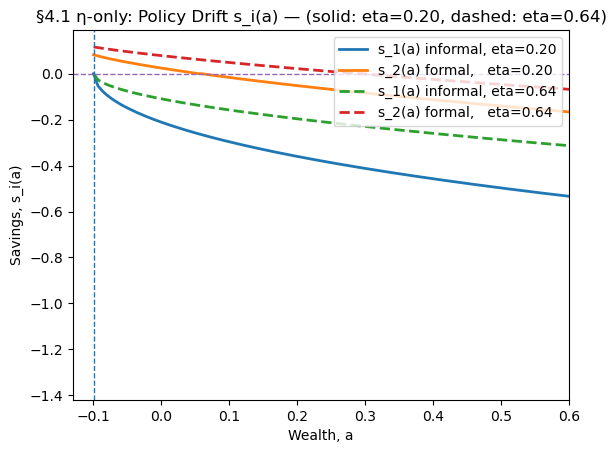

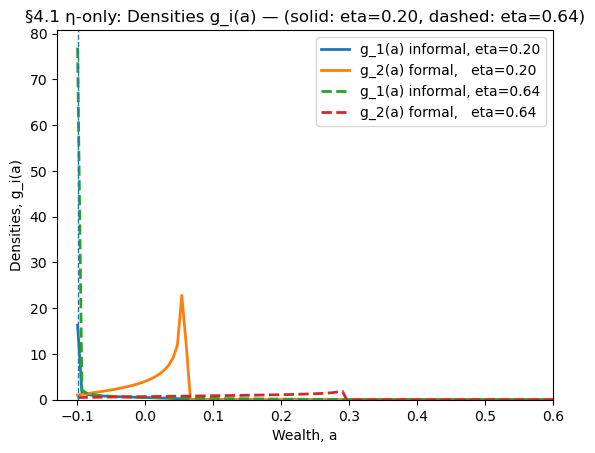

    Section  eta       r*   Mean(a)  Borrowers Mass  Mass Informal  Mass Formal
§4.1 η-only 0.20 0.036693  0.000001        0.406753           0.20         0.80
§4.1 η-only 0.64 0.034454 -0.000005        0.635950           0.64         0.36


In [12]:
gamma_41 = np.array([0.15, 0.15])
tau_41   = np.array([0.18, 0.18])
theta_41 = np.array([0.00, 0.00])
res_41, df_41 = run_section("§4.1 η-only", gamma_41, tau_41, theta_41, etas=(0.20, 0.64), verbose=True)

## §4.2 — Taxes: no tax for informal; formal taxed (keep η set)
- γ: $ \gamma_1 = \gamma_2 = 0.15 $
- τ: $ \tau_1 = 0, \ \tau_2 = 0.18 $
- θ: $ \theta_1 = \theta_2 = 0 $

[eta=0.20] iter 01: r=0.030000, S=-8.563476e-02
[eta=0.20] iter 02: r=0.035000, S=-5.647682e-02
[eta=0.20] iter 03: r=0.037500, S=-3.003644e-02
[eta=0.20] iter 04: r=0.038750, S=-1.254723e-02
[eta=0.20] iter 05: r=0.039375, S=-2.624647e-03
[eta=0.20] iter 06: r=0.039688, S=+2.842501e-03
[eta=0.20] iter 07: r=0.039531, S=-1.352726e-04
[eta=0.20] iter 08: r=0.039609, S=+1.537212e-03
[eta=0.20] iter 09: r=0.039570, S=+6.361694e-04
[eta=0.20] iter 10: r=0.039551, S=+1.213681e-04
[eta=0.20] iter 11: r=0.039541, S=+3.434163e-06
[eta=0.20] Equilibrium r* = 0.039541
[§4.2 Taxes] eta=0.20 | r*=0.039541 | mean(a)=0.0000 | borrowers=0.417 | masses (inf,for)=(0.200,0.800)
[eta=0.64] iter 01: r=0.030000, S=-7.913805e-02
[eta=0.64] iter 02: r=0.035000, S=-3.951339e-02
[eta=0.64] iter 03: r=0.037500, S=-3.810018e-03
[eta=0.64] iter 04: r=0.038750, S=+2.058351e-02
[eta=0.64] iter 05: r=0.038125, S=+7.707567e-03
[eta=0.64] iter 06: r=0.037813, S=+1.795549e-03
[eta=0.64] iter 07: r=0.037656, S=-1.046333

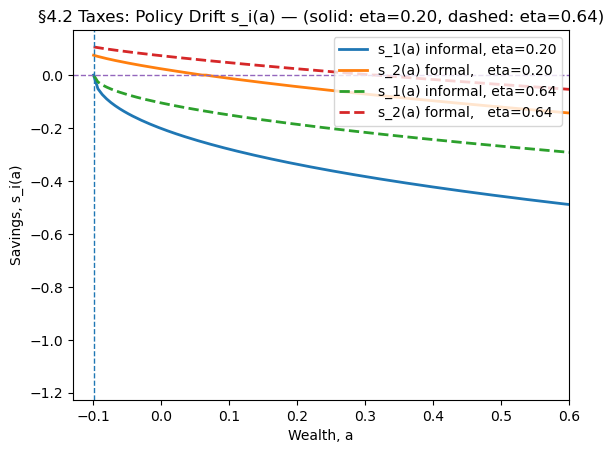

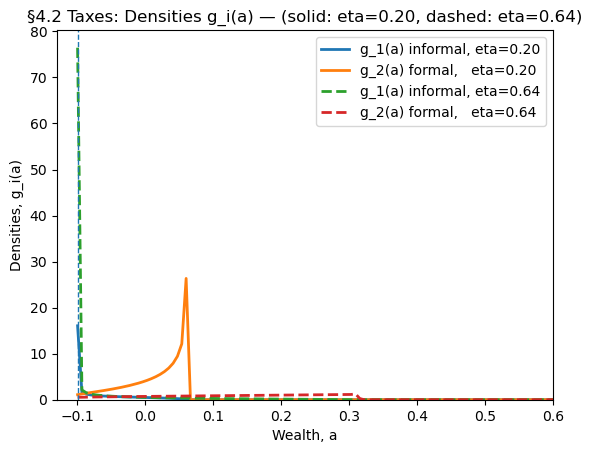

   Section  eta       r*  Mean(a)  Borrowers Mass  Mass Informal  Mass Formal
§4.2 Taxes 0.20 0.039541 0.000003        0.416878           0.20         0.80
§4.2 Taxes 0.64 0.037715 0.000004        0.638599           0.64         0.36


In [13]:
gamma_42 = np.array([0.15, 0.15])
tau_42   = np.array([0.00, 0.18])
theta_42 = np.array([0.00, 0.00])
res_42, df_42 = run_section("§4.2 Taxes", gamma_42, tau_42, theta_42, etas=(0.20, 0.64), verbose=True)

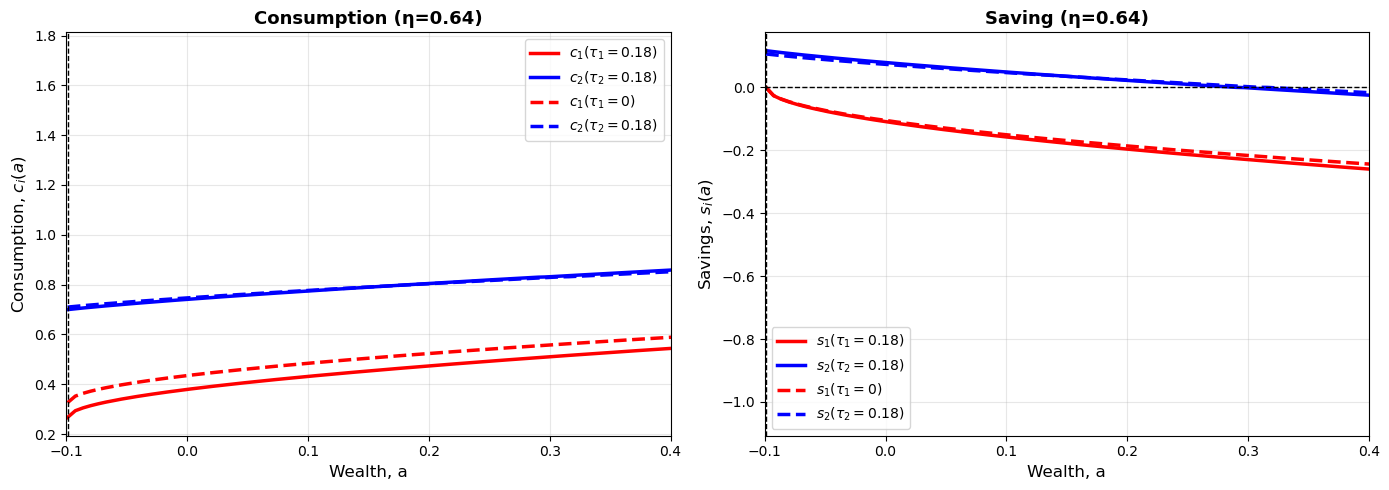

In [14]:

# Comparison plot: §4.1 vs §4.2 for η=0.64
eta_focus = 0.64
a_plot = base_params["a"]
amin_plot = base_params["amin"]
c_41 = res_41[eta_focus].c
c_42 = res_42[eta_focus].c
adot_41 = res_41[eta_focus].adot
adot_42 = res_42[eta_focus].adot

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: Consumption comparison
ax1.plot(a_plot, c_41[:,0], color='red', linestyle='-', linewidth=2.5, label=r'$c_1(\tau_1=0.18)$')
ax1.plot(a_plot, c_41[:,1], color='blue', linestyle='-', linewidth=2.5, label=r'$c_2(\tau_2=0.18)$')
ax1.plot(a_plot, c_42[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$c_1(\tau_1=0)$')
ax1.plot(a_plot, c_42[:,1], color='blue', linestyle='--', linewidth=2.5, label=r'$c_2(\tau_2=0.18)$')
ax1.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax1.set_xlabel('Wealth, a', fontsize=12)
ax1.set_ylabel('Consumption, $c_i(a)$', fontsize=12)
ax1.set_xlim([-0.1, 0.4])
ax1.set_title('Consumption (η=0.64)', fontsize=13, fontweight='bold')
ax1.legend(loc='best', fontsize=10)
ax1.grid(alpha=0.3)

# Right panel: Saving comparison
ax2.plot(a_plot, adot_41[:,0], color='red', linestyle='-', linewidth=2.5, label=r'$s_1(\tau_1=0.18)$')
ax2.plot(a_plot, adot_41[:,1], color='blue', linestyle='-', linewidth=2.5, label=r'$s_2(\tau_2=0.18)$')
ax2.plot(a_plot, adot_42[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$s_1(\tau_1=0)$')
ax2.plot(a_plot, adot_42[:,1], color='blue', linestyle='--', linewidth=2.5, label=r'$s_2(\tau_2=0.18)$')
ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax2.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Wealth, a', fontsize=12)
ax2.set_ylabel('Savings, $s_i(a)$', fontsize=12)
ax2.set_xlim([-0.1, 0.4])
ax2.set_title('Saving (η=0.64)', fontsize=13, fontweight='bold')
ax2.legend(loc='best', fontsize=10)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


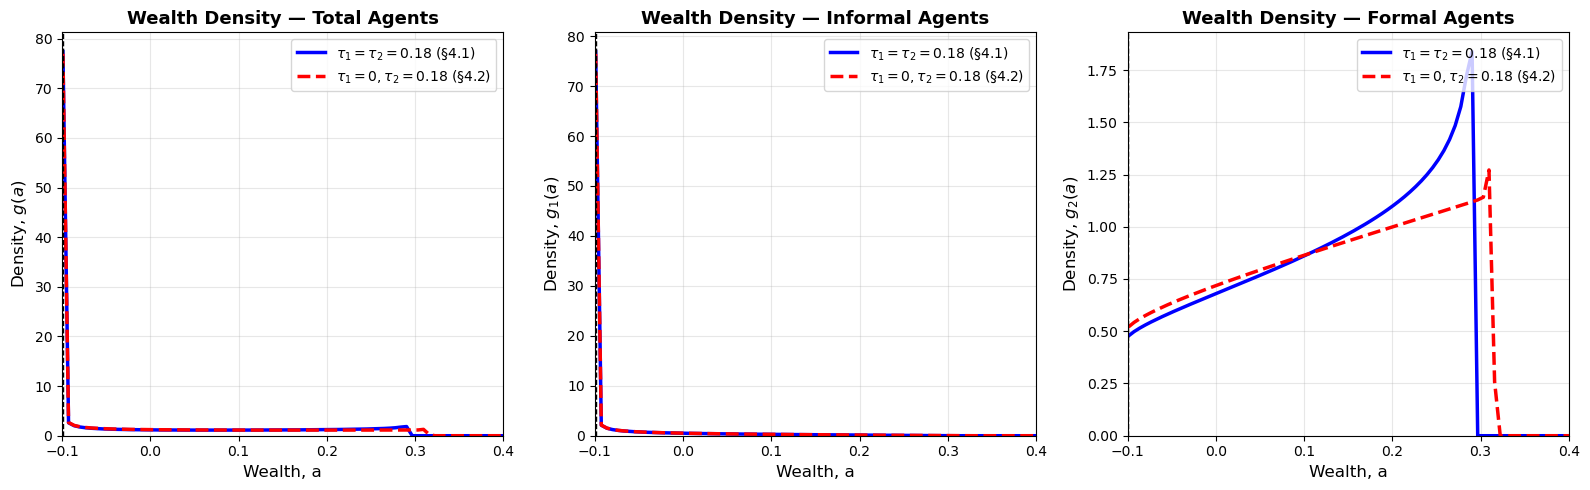

In [15]:

# Distribution comparison plot: §4.1 vs §4.2 for η=0.64 (overlaid with solid/dashed)
eta_focus = 0.64
g_41 = res_41[eta_focus].g
g_42 = res_42[eta_focus].g
g_total_41 = g_41[:,0] + g_41[:,1]
g_total_42 = g_42[:,0] + g_42[:,1]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Total agents (informal + formal)
ax = axes[0]
ax.plot(a_plot, g_total_41, color='blue', linestyle='-', linewidth=2.5, label=r'$\tau_1=\tau_2=0.18$ (§4.1)')
ax.plot(a_plot, g_total_42, color='red', linestyle='--', linewidth=2.5, label=r'$\tau_1=0, \tau_2=0.18$ (§4.2)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Total Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 2: Informal agents
ax = axes[1]
ax.plot(a_plot, g_41[:,0], color='blue', linestyle='-', linewidth=2.5, label=r'$\tau_1=\tau_2=0.18$ (§4.1)')
ax.plot(a_plot, g_42[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$\tau_1=0, \tau_2=0.18$ (§4.2)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_1(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Informal Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 3: Formal agents
ax = axes[2]
ax.plot(a_plot, g_41[:,1], color='blue', linestyle='-', linewidth=2.5, label=r'$\tau_1=\tau_2=0.18$ (§4.1)')
ax.plot(a_plot, g_42[:,1], color='red', linestyle='--', linewidth=2.5, label=r'$\tau_1=0, \tau_2=0.18$ (§4.2)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_2(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Formal Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## §4.3 — Borrowing premium for informal borrowers (when a<0)
- γ: $ \gamma_1 = \gamma_2 = 0.15 $
- τ: $ \tau_1 = 0, \ \tau_2 = 0.18 $
- θ: $ \theta_1 = 0.02, \ \theta_2 = 0 $

[eta=0.20] iter 01: r=0.030000, S=-8.133989e-02
[eta=0.20] iter 02: r=0.035000, S=-4.106397e-02
[eta=0.20] iter 03: r=0.037500, S=-1.110144e-02
[eta=0.20] iter 04: r=0.038750, S=+7.572966e-03
[eta=0.20] iter 05: r=0.038125, S=-1.788036e-03
[eta=0.20] iter 06: r=0.038438, S=+2.876294e-03
[eta=0.20] iter 07: r=0.038281, S=+9.429455e-05
[eta=0.20] iter 08: r=0.038203, S=-7.271709e-04
[eta=0.20] iter 09: r=0.038242, S=-3.061990e-04
[eta=0.20] iter 10: r=0.038262, S=-9.704107e-05
[eta=0.20] iter 11: r=0.038271, S=+4.979840e-06
[eta=0.20] Equilibrium r* = 0.038271
[§4.3 Premium] eta=0.20 | r*=0.038271 | mean(a)=0.0000 | borrowers=0.403 | masses (inf,for)=(0.200,0.800)
[eta=0.64] iter 01: r=0.030000, S=-5.826575e-02
[eta=0.64] iter 02: r=0.035000, S=-9.272347e-03
[eta=0.64] iter 03: r=0.037500, S=+3.362423e-02
[eta=0.64] iter 04: r=0.036250, S=+9.938766e-03
[eta=0.64] iter 05: r=0.035625, S=-1.666765e-04
[eta=0.64] iter 06: r=0.035938, S=+4.744074e-03
[eta=0.64] iter 07: r=0.035781, S=+2.2796

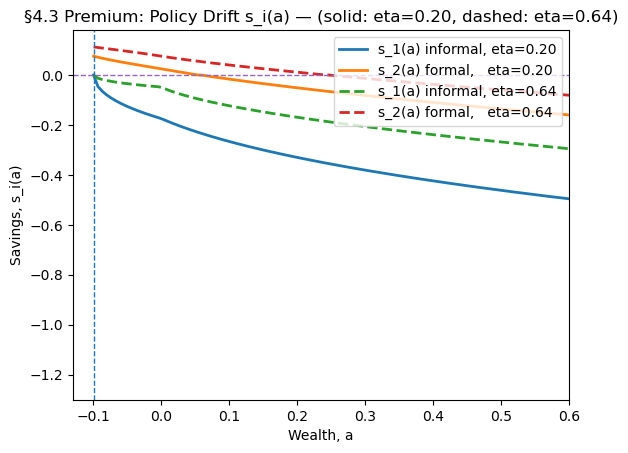

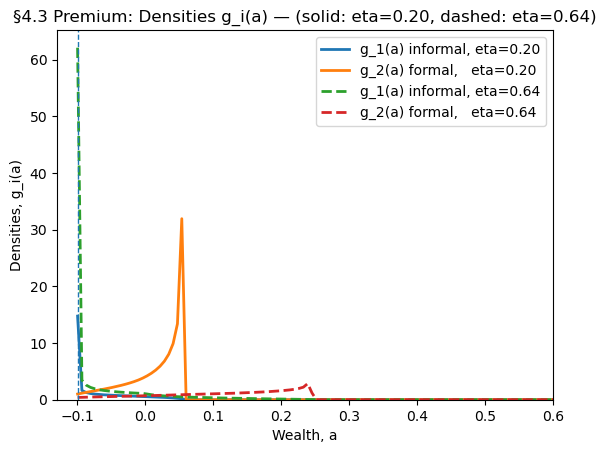

     Section  eta       r*   Mean(a)  Borrowers Mass  Mass Informal  Mass Formal
§4.3 Premium 0.20 0.038271  0.000005        0.402734           0.20         0.80
§4.3 Premium 0.64 0.035635 -0.000002        0.612210           0.64         0.36


In [16]:
gamma_43 = np.array([0.15, 0.15])
tau_43   = np.array([0.00, 0.18])
theta_43 = np.array([0.02, 0.00])
res_43, df_43 = run_section("§4.3 Premium", gamma_43, tau_43, theta_43, etas=(0.20, 0.64), verbose=True)

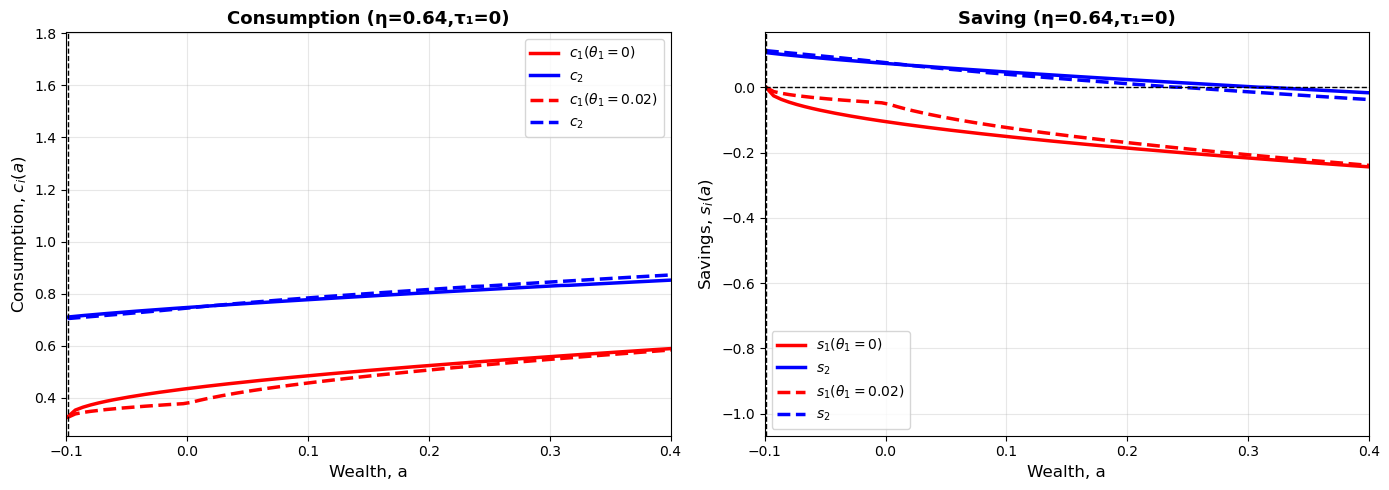

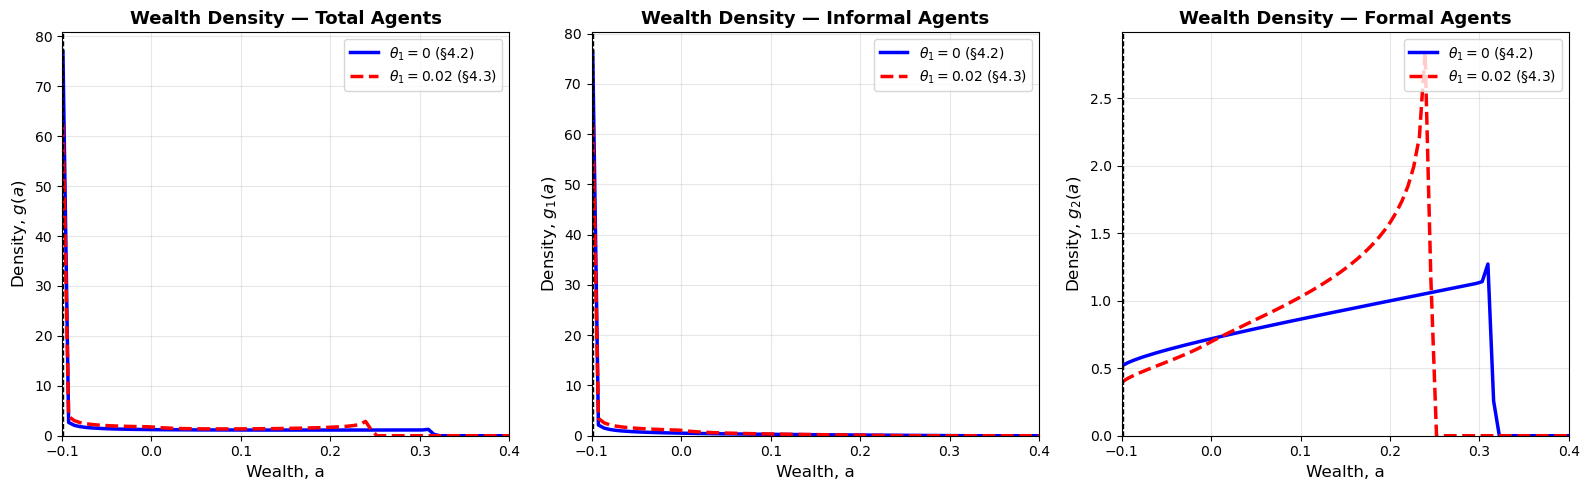

In [17]:

# Comparison plot: §4.2 vs §4.3 for η=0.64 (effect of borrowing premium)
eta_focus = 0.64
a_plot = base_params["a"]
amin_plot = base_params["amin"]
c_42 = res_42[eta_focus].c
c_43 = res_43[eta_focus].c
adot_42 = res_42[eta_focus].adot
adot_43 = res_43[eta_focus].adot

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: Consumption comparison
ax1.plot(a_plot, c_42[:,0], color='red', linestyle='-', linewidth=2.5, label=r'$c_1(\theta_1=0)$')
ax1.plot(a_plot, c_42[:,1], color='blue', linestyle='-', linewidth=2.5, label=r'$c_2$')
ax1.plot(a_plot, c_43[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$c_1(\theta_1=0.02)$')
ax1.plot(a_plot, c_43[:,1], color='blue', linestyle='--', linewidth=2.5, label=r'$c_2$')
ax1.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax1.set_xlabel('Wealth, a', fontsize=12)
ax1.set_ylabel('Consumption, $c_i(a)$', fontsize=12)
ax1.set_xlim([-0.1, 0.4])
ax1.set_title('Consumption (η=0.64,τ₁=0)', fontsize=13, fontweight='bold')
ax1.legend(loc='best', fontsize=10)
ax1.grid(alpha=0.3)

# Right panel: Saving comparison
ax2.plot(a_plot, adot_42[:,0], color='red', linestyle='-', linewidth=2.5, label=r'$s_1(\theta_1=0)$')
ax2.plot(a_plot, adot_42[:,1], color='blue', linestyle='-', linewidth=2.5, label=r'$s_2$')
ax2.plot(a_plot, adot_43[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$s_1(\theta_1=0.02)$')
ax2.plot(a_plot, adot_43[:,1], color='blue', linestyle='--', linewidth=2.5, label=r'$s_2$')
ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax2.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Wealth, a', fontsize=12)
ax2.set_ylabel('Savings, $s_i(a)$', fontsize=12)
ax2.set_xlim([-0.1, 0.4])
ax2.set_title('Saving (η=0.64,τ₁=0)', fontsize=13, fontweight='bold')
ax2.legend(loc='best', fontsize=10)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Distribution comparison plot: §4.2 vs §4.3 for η=0.64
g_42 = res_42[eta_focus].g
g_43 = res_43[eta_focus].g
g_total_42 = g_42[:,0] + g_42[:,1]
g_total_43 = g_43[:,0] + g_43[:,1]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Total agents
ax = axes[0]
ax.plot(a_plot, g_total_42, color='blue', linestyle='-', linewidth=2.5, label=r'$\theta_1=0$ (§4.2)')
ax.plot(a_plot, g_total_43, color='red', linestyle='--', linewidth=2.5, label=r'$\theta_1=0.02$ (§4.3)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Total Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 2: Informal agents
ax = axes[1]
ax.plot(a_plot, g_42[:,0], color='blue', linestyle='-', linewidth=2.5, label=r'$\theta_1=0$ (§4.2)')
ax.plot(a_plot, g_43[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$\theta_1=0.02$ (§4.3)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_1(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Informal Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 3: Formal agents
ax = axes[2]
ax.plot(a_plot, g_42[:,1], color='blue', linestyle='-', linewidth=2.5, label=r'$\theta_1=0$ (§4.2)')
ax.plot(a_plot, g_43[:,1], color='red', linestyle='--', linewidth=2.5, label=r'$\theta_1=0.02$ (§4.3)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_2(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Formal Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## §4.4 — Preference heterogeneity (γ1 > γ2)
- γ: $ \gamma_1 = 0.30, \ \gamma_2 = 0.15 $
- τ: $ \tau_1 = 0, \ \tau_2 = 0.18 $
- θ: $ \theta_1 = 0.02, \ \theta_2 = 0 $

[eta=0.20] iter 01: r=0.030000, S=+8.156161e-02
[eta=0.20] iter 02: r=0.020000, S=-1.009138e-02
[eta=0.20] iter 03: r=0.025000, S=+2.734059e-02
[eta=0.20] iter 04: r=0.022500, S=+7.004464e-03
[eta=0.20] iter 05: r=0.021250, S=-1.844498e-03
[eta=0.20] iter 06: r=0.021875, S=+2.509075e-03
[eta=0.20] iter 07: r=0.021562, S=-4.214668e-04
[eta=0.20] iter 08: r=0.021719, S=+4.208931e-04
[eta=0.20] iter 09: r=0.021641, S=-1.522388e-04
[eta=0.20] iter 10: r=0.021680, S=-2.441335e-05
[eta=0.20] iter 11: r=0.021699, S=+3.801499e-05
[eta=0.20] iter 12: r=0.021689, S=+6.953753e-06
[eta=0.20] Equilibrium r* = 0.021689
[§4.4 Risk Aversion] eta=0.20 | r*=0.021689 | mean(a)=0.0000 | borrowers=0.359 | masses (inf,for)=(0.200,0.800)
[eta=0.64] iter 01: r=0.030000, S=+1.762520e-01
[eta=0.64] iter 02: r=0.020000, S=+2.896162e-02
[eta=0.64] iter 03: r=0.015000, S=-1.120667e-02
[eta=0.64] iter 04: r=0.017500, S=+7.100331e-03
[eta=0.64] iter 05: r=0.016250, S=-2.389882e-03
[eta=0.64] iter 06: r=0.016875, S=+

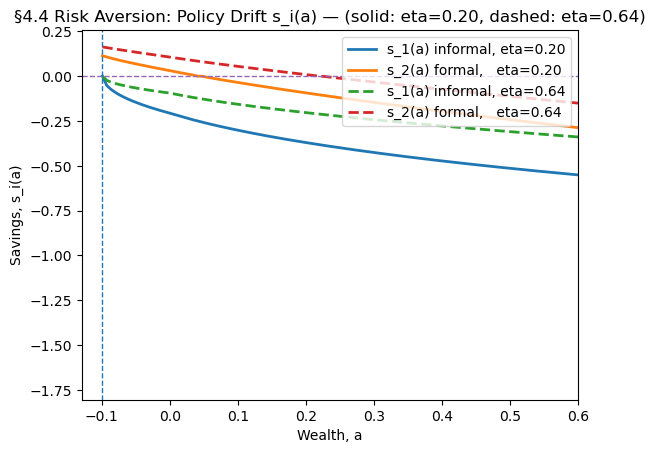

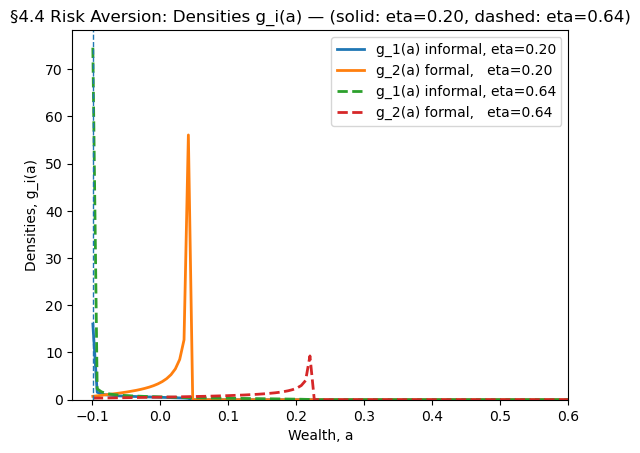

           Section  eta       r*  Mean(a)  Borrowers Mass  Mass Informal  Mass Formal
§4.4 Risk Aversion 0.20 0.021689 0.000007        0.359354           0.20         0.80
§4.4 Risk Aversion 0.64 0.016587 0.000001        0.616971           0.64         0.36


In [18]:
gamma_44 = np.array([0.30, 0.15])
tau_44   = np.array([0.00, 0.18])
theta_44 = np.array([0.02, 0.00])
res_44, df_44 = run_section("§4.4 Risk Aversion", gamma_44, tau_44, theta_44, etas=(0.20, 0.64), verbose=True)

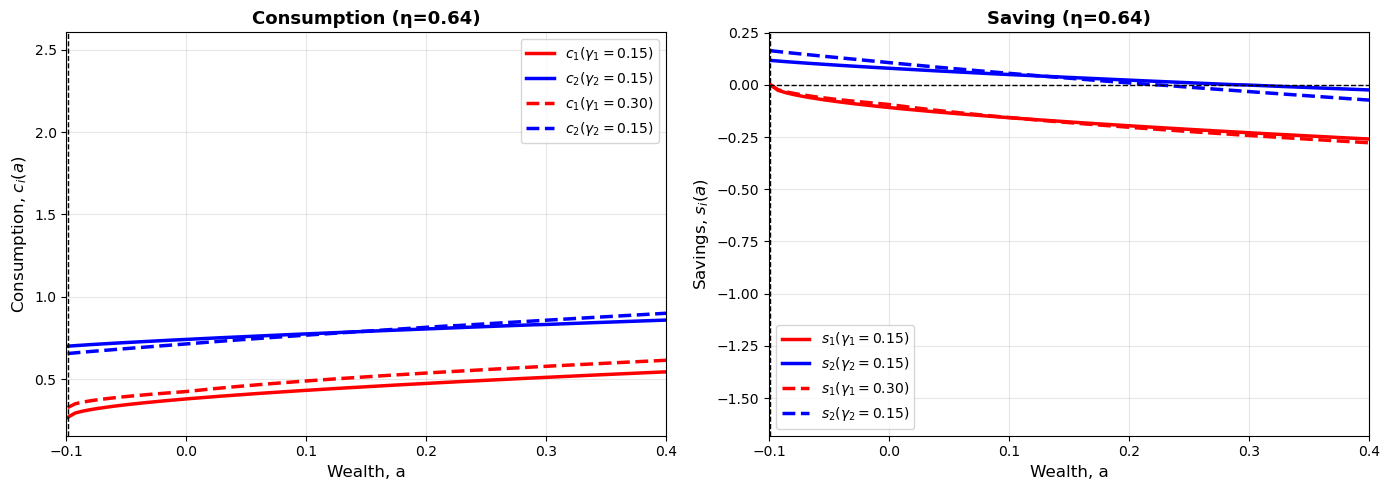

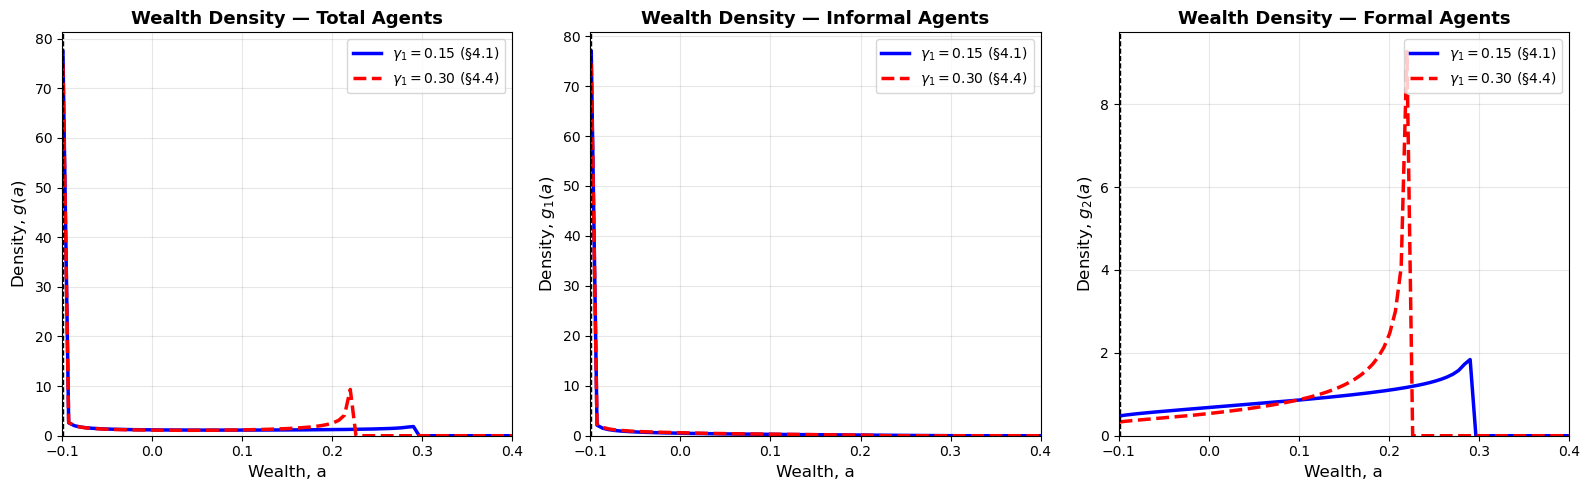

In [22]:

# Comparison plot: §4.3 vs §4.4 for η=0.64 (effect of preference heterogeneity)
eta_focus = 0.64
a_plot = base_params["a"]
amin_plot = base_params["amin"]
c_41 = res_41[eta_focus].c
c_44 = res_44[eta_focus].c
adot_41 = res_41[eta_focus].adot
adot_44 = res_44[eta_focus].adot

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: Consumption comparison
ax1.plot(a_plot, c_41[:,0], color='red', linestyle='-', linewidth=2.5, label=r'$c_1(\gamma_1=0.15)$')
ax1.plot(a_plot, c_41[:,1], color='blue', linestyle='-', linewidth=2.5, label=r'$c_2(\gamma_2=0.15)$')
ax1.plot(a_plot, c_44[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$c_1(\gamma_1=0.30)$')
ax1.plot(a_plot, c_44[:,1], color='blue', linestyle='--', linewidth=2.5, label=r'$c_2(\gamma_2=0.15)$')
ax1.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax1.set_xlabel('Wealth, a', fontsize=12)
ax1.set_ylabel('Consumption, $c_i(a)$', fontsize=12)
ax1.set_xlim([-0.1, 0.4])
ax1.set_title('Consumption (η=0.64)', fontsize=13, fontweight='bold')
ax1.legend(loc='best', fontsize=10)
ax1.grid(alpha=0.3)

# Right panel: Saving comparison
ax2.plot(a_plot, adot_41[:,0], color='red', linestyle='-', linewidth=2.5, label=r'$s_1(\gamma_1=0.15)$')
ax2.plot(a_plot, adot_41[:,1], color='blue', linestyle='-', linewidth=2.5, label=r'$s_2(\gamma_2=0.15)$')
ax2.plot(a_plot, adot_44[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$s_1(\gamma_1=0.30)$')
ax2.plot(a_plot, adot_44[:,1], color='blue', linestyle='--', linewidth=2.5, label=r'$s_2(\gamma_2=0.15)$')
ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax2.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Wealth, a', fontsize=12)
ax2.set_ylabel('Savings, $s_i(a)$', fontsize=12)
ax2.set_xlim([-0.1, 0.4])
ax2.set_title('Saving (η=0.64)', fontsize=13, fontweight='bold')
ax2.legend(loc='best', fontsize=10)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Distribution comparison plot: §4.3 vs §4.4 for η=0.64
g_41 = res_41[eta_focus].g
g_44 = res_44[eta_focus].g
g_total_41 = g_41[:,0] + g_41[:,1]
g_total_44 = g_44[:,0] + g_44[:,1]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Total agents
ax = axes[0]
ax.plot(a_plot, g_total_41, color='blue', linestyle='-', linewidth=2.5, label=r'$\gamma_1=0.15$ (§4.1)')
ax.plot(a_plot, g_total_44, color='red', linestyle='--', linewidth=2.5, label=r'$\gamma_1=0.30$ (§4.4)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Total Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 2: Informal agents
ax = axes[1]
ax.plot(a_plot, g_41[:,0], color='blue', linestyle='-', linewidth=2.5, label=r'$\gamma_1=0.15$ (§4.1)')
ax.plot(a_plot, g_44[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$\gamma_1=0.30$ (§4.4)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_1(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Informal Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 3: Formal agents
ax = axes[2]
ax.plot(a_plot, g_41[:,1], color='blue', linestyle='-', linewidth=2.5, label=r'$\gamma_1=0.15$ (§4.1)')
ax.plot(a_plot, g_44[:,1], color='red', linestyle='--', linewidth=2.5, label=r'$\gamma_1=0.30$ (§4.4)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_2(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Formal Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Final summary

In [20]:
import pandas as pd
df_all = pd.concat([df_41, df_42, df_43, df_44], ignore_index=True)
try:
    from caas_jupyter_tools import display_dataframe_to_user
    display_dataframe_to_user("Galindo §4.1–§4.4 — Summary", df_all)
except Exception:
    print(df_all.to_string(index=False))

           Section  eta       r*   Mean(a)  Borrowers Mass  Mass Informal  Mass Formal
       §4.1 η-only 0.20 0.036693  0.000001        0.406753           0.20         0.80
       §4.1 η-only 0.64 0.034454 -0.000005        0.635950           0.64         0.36
        §4.2 Taxes 0.20 0.039541  0.000003        0.416878           0.20         0.80
        §4.2 Taxes 0.64 0.037715  0.000004        0.638599           0.64         0.36
      §4.3 Premium 0.20 0.038271  0.000005        0.402734           0.20         0.80
      §4.3 Premium 0.64 0.035635 -0.000002        0.612210           0.64         0.36
§4.4 Risk Aversion 0.20 0.021689  0.000007        0.359354           0.20         0.80
§4.4 Risk Aversion 0.64 0.016587  0.000001        0.616971           0.64         0.36
